# Xgboost Challenger

In [138]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [139]:
training_dataset_path = "../data/raw/cs-training.csv"
df = pd.read_csv(training_dataset_path)

df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [140]:
if "Unnamed: 0" in df.columns:
    df = df.drop(columns = ["Unnamed: 0"])

df = df[df["age"] > 0]
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")

Total Rows: 149999, Total Columns: 11


In [141]:
X = df.drop(columns = ["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

print(X.shape)
print(y.shape)

(149999, 10)
(149999,)


In [142]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify = y, random_state = 42
)

In [143]:
print(y_train.mean())
print(y_test.mean())

0.0668361496546636
0.06685333333333333


### Feature Engineering

In [144]:
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    late_col = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]
    df["TotalDelinquency"] = df[late_col[0]] + df[late_col[1]] + df[late_col[2]]
    df["IncomePerPerson"] = df["MonthlyIncome"] / (df["NumberOfDependents"].fillna(0) + 1)
    df["IncomeMissing"] = df["MonthlyIncome"].isna().astype(int)
    df["IsBureauFrozen"] = df[late_col].isin([98, 96]).sum(axis = 1)
    df["EstimatedDollarDebt"] = df["MonthlyIncome"] * df["DebtRatio"]

    return df

### Training and Testing

In [145]:
X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

print(X_train_fe.shape)
print(X_test_fe.shape)

(112499, 15)
(37500, 15)


In [146]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

In [147]:
clf = XGBClassifier(n_estimators = 200, learning_rate = 0.05, max_depth = 8, subsample = 0.8, colsapmle_bytree = 0.8, eval_metric = "auc", random_state = 42).fit(X_train_fe, y_train)

/media/divyanshu/MyStorage1/Learning/01_Credit_Fraud/venv/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [16:35:36] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "colsapmle_bytree" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [148]:
y_pred = clf.predict_proba(X_test_fe)[:,1]

In [149]:
auc_roc = roc_auc_score(y_test, y_pred)

gini_coef = 2 * auc_roc - 1

print(f"AUC-ROC Score: {auc_roc}")
print(f"Gini Coefficient: {gini_coef}")

AUC-ROC Score: 0.8655224406326362
Gini Coefficient: 0.7310448812652723


### Good Vs Bad

In [150]:
good_pred = y_pred[y_test == 0]
bad_pred = y_pred[y_test == 1]

ks_stat, p_value = ks_2samp(good_pred, bad_pred)
print(f"KS Statistic: {ks_stat*100:.2f}% (p-value: {p_value})")

KS Statistic: 57.63% (p-value: 0.0)


### Interpretability using SHAP

In [151]:
import shap

explainer = shap.TreeExplainer(clf)

In [152]:
sample_X = X_test_fe.sample(2000, random_state = 42)
shap_values = explainer(sample_X)

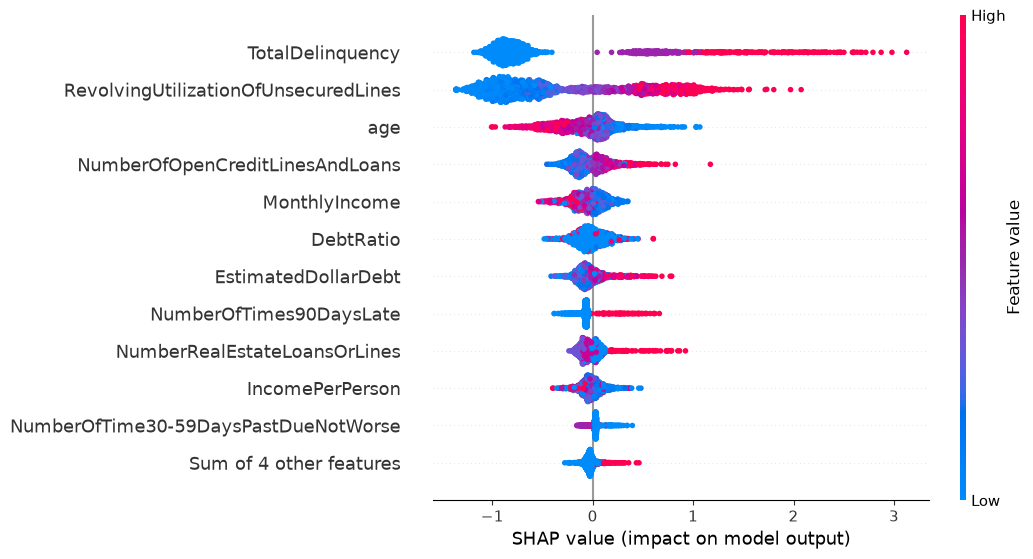

In [153]:
shap.plots.beeswarm(shap_values, max_display = 12)

In [154]:
sample_probs = clf.predict_proba(sample_X)[:, 1]

high_risk_idx = np.argmax(sample_probs)

print(f"High Risk Index: {high_risk_idx}, Default Prob: {sample_probs[high_risk_ids]:.2%}")

High Risk Index: 423, Default Prob: 85.05%


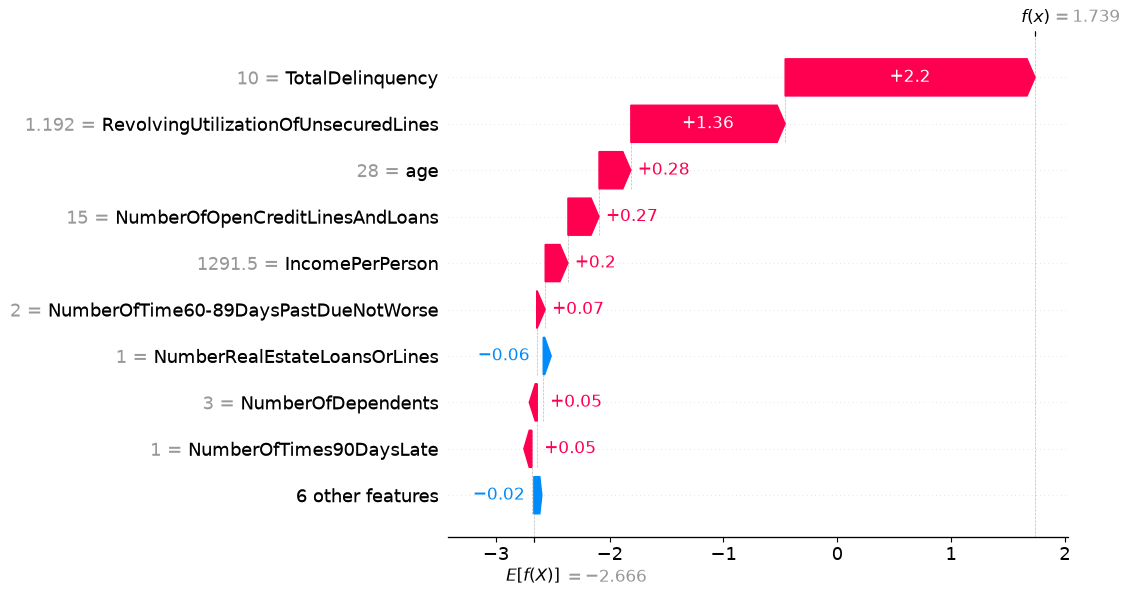

In [155]:
shap.plots.waterfall(shap_values[high_risk_idx])

### Kaggle Submission

In [156]:
test_database_path = "../data/raw/cs-test.csv"

df = pd.read_csv(test_database_path)
X = df.copy()
if "Unnamed: 0" in X.columns or "SeriousDlqin2yrs" in X.columns:
    X = X.drop(columns = ["Unnamed: 0", "SeriousDlqin2yrs"])

y = df["SeriousDlqin2yrs"]

print(X.shape)
print(y.shape)

(101503, 10)
(101503,)


In [157]:
X_fe = engineer_features(X)
print(X_fe.shape)

(101503, 15)


In [158]:
probability = clf.predict_proba(X_fe)[:, 1]

In [159]:
print(probability)

[0.04823973 0.03420443 0.02118393 ... 0.00385435 0.04808655 0.0320645 ]


In [160]:
submission = pd.DataFrame({
    "Id": df["Unnamed: 0"],
    "Probability": probability
})
print(submission)

            Id  Probability
0            1     0.048240
1            2     0.034204
2            3     0.021184
3            4     0.062953
4            5     0.142485
...        ...          ...
101498  101499     0.034927
101499  101500     0.350529
101500  101501     0.003854
101501  101502     0.048087
101502  101503     0.032065

[101503 rows x 2 columns]


In [161]:
pd.Series(probability).describe()

count    101503.000000
mean          0.065848
std           0.120707
min           0.000711
25%           0.007769
50%           0.018739
75%           0.060269
max           0.951692
dtype: float64

In [162]:
import os
os.makedirs("../submissions", exist_ok = True)
submission_path = "../submissions/02_xgboost.csv"
submission.to_csv(submission_path, index = False)
print(f"Saved submission to {submission_path} with shape {submission.shape}")

Saved submission to ../submissions/02_xgboost.csv with shape (101503, 2)
